# Dynamic DeepHit: 5 final seeds, with vs. without actions in the input

Two variants, 5 seeds each:
- **with_actions**: fluid/vaso included in the inputs (latents intended for the RL *state*)
- **without_actions**: treatment removed from the inputs (health score intended for the RL *reward*)

This notebook generates train/val/test predictions for all 10 models (cached to each run's folder), evaluates discrimination/calibration across seeds, checks how consistent the reward is across seeds, and runs the vaso-onset event study.

In [1]:
import sys
import os
from pathlib import Path
import importlib
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch


# Optional but very useful in notebooks
%load_ext autoreload
%autoreload 2

repo_root = Path("/home/jake/Documents/AI_Clinician/ai_clinician_pediatric_rl")
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

import src.supervised_learning.predict as ddh_predict
import src.supervised_learning.evaluate_dynamic_deephit_final_seeds as eval_ddh
from src.rl.analysis import runs as R, models as M, data as D, model_locations as loc

R.set_path_mappings([
    ("/rds/general/user/jormond/home/projects/ai_clinician/data/mimic_iv_3.1_data",
     "/home/jake/Documents/AI_Clinician/mimic_iv_3.1_data"),
    ("/rds/general/user/jormond/home/projects/ai_clinician/code",
     "/home/jake/Documents/imperial_rds_ai_clinician/code"),
    ("/rds/general/user/jormond/home/projects/ai_clinician",
     "/home/jake/Documents/AI_Clinician/models"),
])

[('/rds/general/user/jormond/home/projects/ai_clinician/data/mimic_iv_3.1_data',
  '/home/jake/Documents/AI_Clinician/mimic_iv_3.1_data'),
 ('/rds/general/user/jormond/home/projects/ai_clinician/code',
  '/home/jake/Documents/imperial_rds_ai_clinician/code'),
 ('/rds/general/user/jormond/home/projects/ai_clinician',
  '/home/jake/Documents/AI_Clinician/models')]

# Load models

In [21]:
hospital = "mimic_iv" # "choc"
unit = None # "picu"
actions = "combined_hourly_iv-vasoactive_inotropic_score" # "intake-vis"
actions_inclusion = "with_actions" # "without_actions"

if actions_inclusion == "with_actions":
    predictions_purpose = "for_states" # "for_states", "for_rewards"

if unit is not None:
    DDH_ROOT = f"/home/jake/Documents/AI_Clinician/models/dynamic_deephit_results/{hospital}/split_0/sepsis/{actions}/{unit}/{actions_inclusion}"
else:
    DDH_ROOT = f"/home/jake/Documents/AI_Clinician/models/dynamic_deephit_results/{hospital}/split_0/sepsis/{actions}/{actions_inclusion}"

if actions_inclusion == "with_actions":
    DDH_ROOT = f"{DDH_ROOT}/{predictions_purpose}"

DDH_PREDICTIONS = f"{DDH_ROOT}/five_seeds"
DDH_PREDICTIONS = Path(DDH_PREDICTIONS)
print(f"DDH_PREDICTIONS: {DDH_PREDICTIONS}")

DDH_PREDICTIONS: /home/jake/Documents/AI_Clinician/models/dynamic_deephit_results/mimic_iv/split_0/sepsis/combined_hourly_iv-vasoactive_inotropic_score/with_actions/for_states/five_seeds


In [3]:
study = R.make_study({actions_inclusion: str(DDH_PREDICTIONS)}, family=R.DDH_FAMILY, name="ddh")
assert study.seeds() == [0, 1, 2, 3, 4], study.seeds()
actions_included = [k[0] for k in study.keys]

table = study.table(["include_actions_in_state", "actions_shift"])
table["run_folder"] = table["run_dir"].map(os.path.basename)
display(table.drop(columns=["run_dir", "data"]))

# full location of each variant's runs, once
for actions in actions_included:
    job_dirs = {os.path.dirname(r.run_dir) for r in study.group(actions).values()}
    print(f"{actions}: {', '.join(sorted(job_dirs))}")

family include_actions_in_state  actions_shift  \
group        seed                                                            
with_actions 0     dynamic_deephit                     True          False   
             1     dynamic_deephit                     True          False   
             2     dynamic_deephit                     True          False   
             3     dynamic_deephit                     True          False   
             4     dynamic_deephit                     True          False   

                   n_overrides                                 run_folder  
group        seed                                                          
with_actions 0               0  unknown_cx3-20-4_20261030-011546_0054a679  
             1               0  unknown_cx3-20-4_20261030-023020_ecbe94b1  
             2               0  unknown_cx3-20-4_20261030-034655_b543b11d  
             3               0  unknown_cx3-20-4_20261030-050210_142f0b48  
             4               0  unknown_cx3-20-4_20261030-064005_1d3fade5

with_actions: /home/jake/Documents/AI_Clinician/models/dynamic_deephit_results/mimic_iv/split_0/sepsis/combined_hourly_iv-vasoactive_inotropic_score/with_actions/for_rewards/five_seeds/mimic_iv_dynamic_deephit_transformer_discharge_mortality_tte_standard_split_0_20261030_011429_926622_job4502771.pbs-7


note that actions_shift in the without_actions model has no effect.

In [4]:
ddh_models = eval_ddh.load_ddh_models(study)   # {variant: {seed: LoadedModel}}, ordered by seed

config_managers = {actions: seeds[min(seeds)].config_manager for actions, seeds in ddh_models.items()}

# check the remapped paths point at local files
for actions, cm in config_managers.items():
    path = eval_ddh.dataset_filepath(cm, "test")
    print(f"{actions}: {path}  exists: {os.path.exists(path)}")

/home/jake/Documents/AI_Clinician/ai_clinician_pediatric_rl/src/rl/analysis/models.py:389: UserWarning: ddh with_actions seed 0: load_configuration failed (KeyError: 'config_dir'); using the raw config_manager.pkl
  warnings.warn(f"{record.label}: load_configuration failed ({type(e).__name__}: {e}); "


  loaded LoadedModel(ddh with_actions seed 0: model)
  loaded LoadedModel(ddh with_actions seed 1: model)


/home/jake/Documents/AI_Clinician/ai_clinician_pediatric_rl/src/rl/analysis/models.py:389: UserWarning: ddh with_actions seed 1: load_configuration failed (KeyError: 'config_dir'); using the raw config_manager.pkl
  warnings.warn(f"{record.label}: load_configuration failed ({type(e).__name__}: {e}); "
/home/jake/Documents/AI_Clinician/ai_clinician_pediatric_rl/src/rl/analysis/models.py:389: UserWarning: ddh with_actions seed 2: load_configuration failed (KeyError: 'config_dir'); using the raw config_manager.pkl
  warnings.warn(f"{record.label}: load_configuration failed ({type(e).__name__}: {e}); "


  loaded LoadedModel(ddh with_actions seed 2: model)
  loaded LoadedModel(ddh with_actions seed 3: model)


/home/jake/Documents/AI_Clinician/ai_clinician_pediatric_rl/src/rl/analysis/models.py:389: UserWarning: ddh with_actions seed 3: load_configuration failed (KeyError: 'config_dir'); using the raw config_manager.pkl
  warnings.warn(f"{record.label}: load_configuration failed ({type(e).__name__}: {e}); "
/home/jake/Documents/AI_Clinician/ai_clinician_pediatric_rl/src/rl/analysis/models.py:389: UserWarning: ddh with_actions seed 4: load_configuration failed (KeyError: 'config_dir'); using the raw config_manager.pkl
  warnings.warn(f"{record.label}: load_configuration failed ({type(e).__name__}: {e}); "


  loaded LoadedModel(ddh with_actions seed 4: model)
with_actions: /home/jake/Documents/AI_Clinician/mimic_iv_3.1_data/combined_data/hourly_all_patients/split_0/training_set/test_dynamic_deephit_dataset.h5  exists: True


# Load data

In [5]:
processors = D.load_ddh_datasets(ddh_models, splits=("train", "val", "test"))

# generate predictions

In [11]:
eval_ddh.run_predictions(
    ddh_models[actions_inclusion], processors,
    splits=("train", "val", "test"), batch_size=512
)

train: 5262278 windows, 167 inputs, actions_shift=False
  verified 448 windows against Dataset.__getitem__
  seed 0: saved to /home/jake/Documents/AI_Clinician/models/dynamic_deephit_results/mimic_iv/split_0/sepsis/combined_hourly_iv-vasoactive_inotropic_score/with_actions/for_rewards/five_seeds/mimic_iv_dynamic_deephit_transformer_discharge_mortality_tte_standard_split_0_20261030_011429_926622_job4502771.pbs-7/unknown_cx3-20-4_20261030-011546_0054a679/train_predictions.h5
  seed 1: saved to /home/jake/Documents/AI_Clinician/models/dynamic_deephit_results/mimic_iv/split_0/sepsis/combined_hourly_iv-vasoactive_inotropic_score/with_actions/for_rewards/five_seeds/mimic_iv_dynamic_deephit_transformer_discharge_mortality_tte_standard_split_0_20261030_011429_926622_job4502771.pbs-7/unknown_cx3-20-4_20261030-023020_ecbe94b1/train_predictions.h5
  seed 2: saved to /home/jake/Documents/AI_Clinician/models/dynamic_deephit_results/mimic_iv/split_0/sepsis/combined_hourly_iv-vasoactive_inotropic_sco

In [ ]:
# plot the prediction trajectories for a few random patients from the test set, for each model
seeds_to_plot = [0, 1, 2, 3, 4] 
for actions in actions_included:
    for seed, m in ddh_models[actions].items():
        if seed not in seeds_to_plot:
            continue
        print(f"{actions} seed {seed}")
        ddh_predict.plot_random_predictions(m.config_manager)

# evaluate similarity of predictions

with_actions: /home/jake/Documents/AI_Clinician/models/dynamic_deephit_results/mimic_iv/split_0/sepsis/combined_hourly_iv-vasoactive_inotropic_score/with_actions/for_rewards/five_seeds/mimic_iv_dynamic_deephit_transformer_discharge_mortality_tte_standard_split_0_20261030_011429_926622_job4502771.pbs-7
with_actions


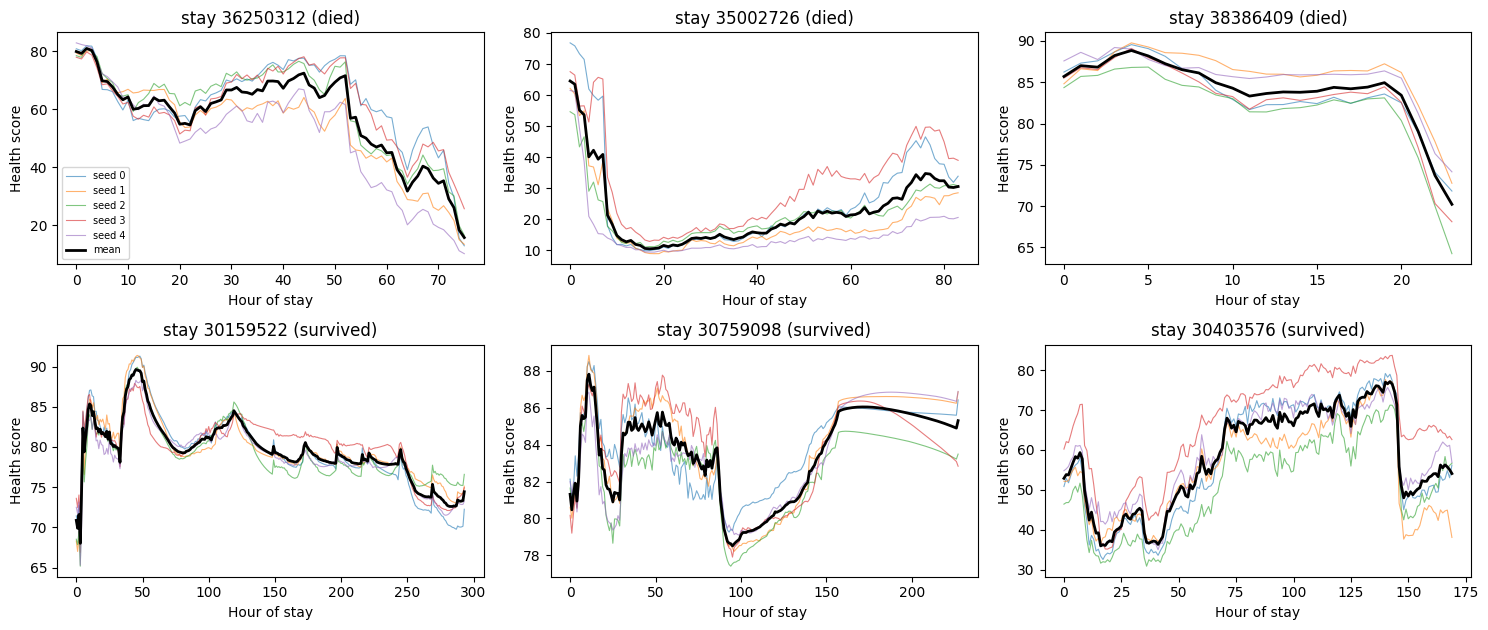

,with_actions
n_seeds,5.000
n_rows,1616902.000
health_score_pearson_mean,0.922
health_score_pearson_min,0.912
health_score_within_stay_pearson_mean,0.831
reward_pearson_mean,0.622
reward_pearson_min,0.596
reward_vs_other_seeds_mean_pearson,0.735
reward_all_seeds_same_sign,0.411
health_score_sd_between_rows,16.478


In [15]:
# Agreement across seeds (test split)
ENSEMBLE_DIRS = {a: eval_ddh.ensemble_dir(ddh_models[a]) for a in actions_included}
for a, d in ENSEMBLE_DIRS.items():
    print(f"{a}: {d}")

agreement = {}
for actions in actions_included:
    hs_by_seed, meta = eval_ddh.load_health_scores(ddh_models[actions], split="test")
    agreement[actions] = eval_ddh.seed_agreement_summary(hs_by_seed, meta["index_ptr"])
    os.makedirs(ENSEMBLE_DIRS[actions], exist_ok=True)
    fig = eval_ddh.plot_seed_trajectories(
        hs_by_seed, meta, dataset=processors["test"], n_stays=6,
        save_path=os.path.join(ENSEMBLE_DIRS[actions], "seed_trajectories_test.png"),
    )
    print(actions)
    display(fig)

agreement_table = pd.concat(agreement, axis=1)
agreement_table.columns = actions_included
agreement_table.round(3)

## these figures justify the ensemble directly. In a sentence: individual-seed hourly rewards share only about 35% of their variance, and averaging five seeds raises the shared component to about 73%, so all RL seeds are trained on the same, less noisy reward. The variants differ only marginally. The action-free version has slightly lower minimum agreement (0.27, between seeds 1 and 3), which doesn't change anything.


=== with_actions: health score Pearson across seeds (test) ===
       0      1      2      3      4
0  1.000  0.933  0.927  0.920  0.921
1  0.933  1.000  0.935  0.919  0.922
2  0.927  0.935  1.000  0.916  0.917
3  0.920  0.919  0.916  1.000  0.912
4  0.921  0.922  0.917  0.912  1.000
off-diagonal mean 0.922, min 0.912, max 0.935


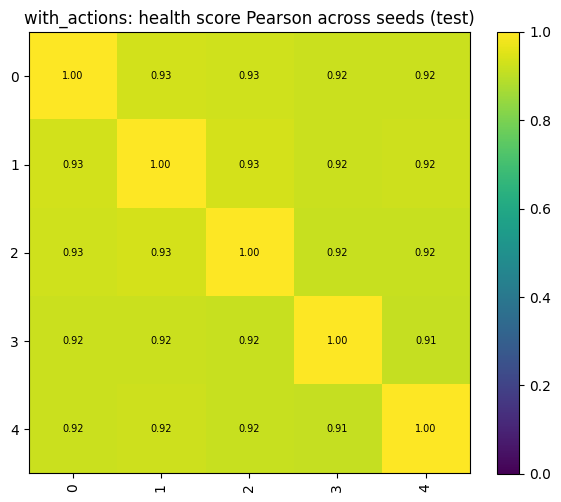


=== with_actions: reward Pearson across seeds (test) ===
       0      1      2      3      4
0  1.000  0.644  0.648  0.608  0.623
1  0.644  1.000  0.646  0.610  0.626
2  0.648  0.646  1.000  0.601  0.619
3  0.608  0.610  0.601  1.000  0.596
4  0.623  0.626  0.619  0.596  1.000
off-diagonal mean 0.622, min 0.596, max 0.648


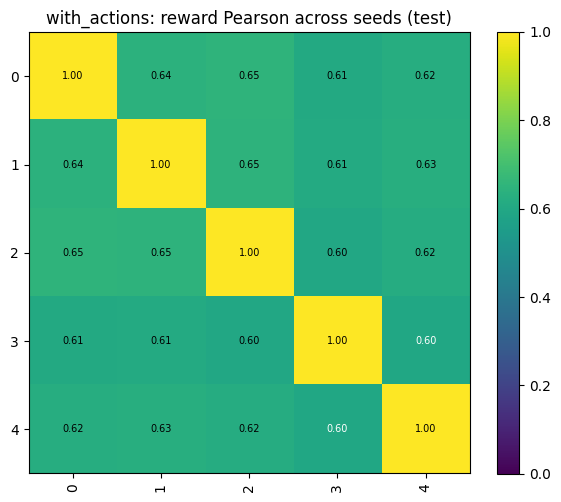

In [16]:
# Pairwise Pearson between seeds, printed for copying (test split)
for actions in actions_included:
    hs_by_seed, meta = eval_ddh.load_health_scores(ddh_models[actions], split="test")
    index_ptr = meta["index_ptr"]
    hs = {s: h for s, h in hs_by_seed.items()}
    rewards = {s: eval_ddh.within_stay_reward(h, index_ptr) for s, h in hs_by_seed.items()}

    for name, series in [("health score", hs), ("reward", rewards)]:
        pearson, _ = eval_ddh.pairwise_agreement(series)
        offdiag = pearson.values[~np.eye(len(pearson), dtype=bool)]
        print(f"\n=== {actions}: {name} Pearson across seeds (test) ===")
        print(pearson.round(3).to_string())
        print(f"off-diagonal mean {offdiag.mean():.3f}, min {offdiag.min():.3f}, max {offdiag.max():.3f}")
        display(eval_ddh.plot_agreement(pearson, f"{actions}: {name} Pearson across seeds (test)"))

# average the rewards
## only run if predictions_purpose is for_rewards, or if actions_inclusion is without_actions
### if predictions_purpose is for_states, then we use the unaveraged seed specific predictions

In [17]:
predictions_purpose

'for_rewards'

In [18]:
if predictions_purpose == "for_states" and actions_inclusion == "with_actions":
    # Build the seed-averaged health score for every split
    for split in ["train", "val", "test"]:
        eval_ddh.build_ensemble_health_score(ddh_models[actions_inclusion], split, processors[split])

In [19]:
if predictions_purpose == "for_states" and actions_inclusion == "with_actions":
    out_dir = eval_ddh.ensemble_dir(ddh_models[actions_inclusion])
    for split in ["train", "val", "test"]:
        ens = eval_ddh.load_ensemble_health_score(eval_ddh.prediction_path(out_dir, split))
        n_rows = ens["index_ptr"][-1]
        print(f"{actions_inclusion:16s} {split:5s} rows={n_rows:7d}  health_score={ens['health_score'].shape}  "
              f"seeds={list(ens['seeds'])}  matches rows: {len(ens['health_score']) == n_rows}")

In [20]:
if predictions_purpose == "for_states" and actions_inclusion == "with_actions":
    N_STAYS = 9
    hs_by_seed, meta = eval_ddh.load_health_scores(ddh_models[actions_inclusion], split="test")
    out_dir = eval_ddh.ensemble_dir(ddh_models[actions_inclusion])
    ensemble = eval_ddh.load_ensemble_health_score(eval_ddh.prediction_path(out_dir, "test"))

    fig = eval_ddh.plot_seed_trajectories(
        hs_by_seed, meta, dataset=processors["test"], ensemble=ensemble,
        n_stays=N_STAYS, rng_seed=0,
        save_path=os.path.join(out_dir, "seed_trajectories_with_ensemble_test.png"),
    )
    print(actions_inclusion)
    display(fig)